# 01 Mountain masks: checks
GMBA v2.0 standard mountains on the native grid of each CORDEX-CMIP6 12 km domain (RegCM5-0).
Variables are described in `masks/README.md`. Run after `scripts/03_build_masks.py`.

In [1]:
import glob, os
import numpy as np, pandas as pd, netCDF4 as nc
import matplotlib.pyplot as plt
import cartopy.crs as ccrs, cartopy.feature as cfeature

MTN = os.environ.get("MTN_DIR", os.path.abspath(".."))  # project folder (notebooks/ is one level down)
DOMAINS = ["AFR-12", "AUS-12", "EAS-12", "EUR-12", "NAM-12", "SAM-12"]
# Fixed colour per domain (validated for colour-vision deficiency; every domain is also labelled by name).
DOM_COL = dict(zip(DOMAINS, ["#0072B2", "#009E73", "#D55E00", "#CC79A7", "#E69F00", "#56B4E9"]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "font.size": 9})

def load_mask(dom):
    with nc.Dataset(f"{MTN}/masks/{dom}_mountain_mask.nc") as d:
        m = {k: d[k][:].filled(np.nan) if np.ma.isMaskedArray(d[k][:]) else d[k][:] for k in d.variables}
    # Unwrap longitude around the domain centre so maps work across the dateline (EAS-12, AUS-12).
    c = m["lon"][m["lon"].shape[0] // 2, m["lon"].shape[1] // 2]
    m["lonu"] = c + (m["lon"] - c + 180) % 360 - 180
    m["clon"] = float(c)
    return m


## Mountain area by covering domains
Area of GMBA mountains (M km²) by which domains cover it. `NONE` = not covered by any 12 km domain.

In [2]:
ov = pd.read_csv(f"{MTN}/masks/overlap_area_by_domains.csv")
ov.round(3)

,domains,area_Mkm2,pct
0,EAS-12,10.530,42.483
1,NAM-12,4.155,16.765
2,SAM-12,3.010,12.144
3,AFR-12,2.639,10.647
4,AFR-12+EUR-12,1.146,4.622
5,NONE,1.120,4.517
6,EUR-12,0.889,3.586
7,AUS-12+EAS-12,0.648,2.616
8,AUS-12,0.645,2.604
9,AFR-12+EAS-12,0.003,0.013


## Global coverage
Grey shading: GMBA mountain fraction at 0.25°. Coloured outlines: area of each domain (mountain pixels only).

/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


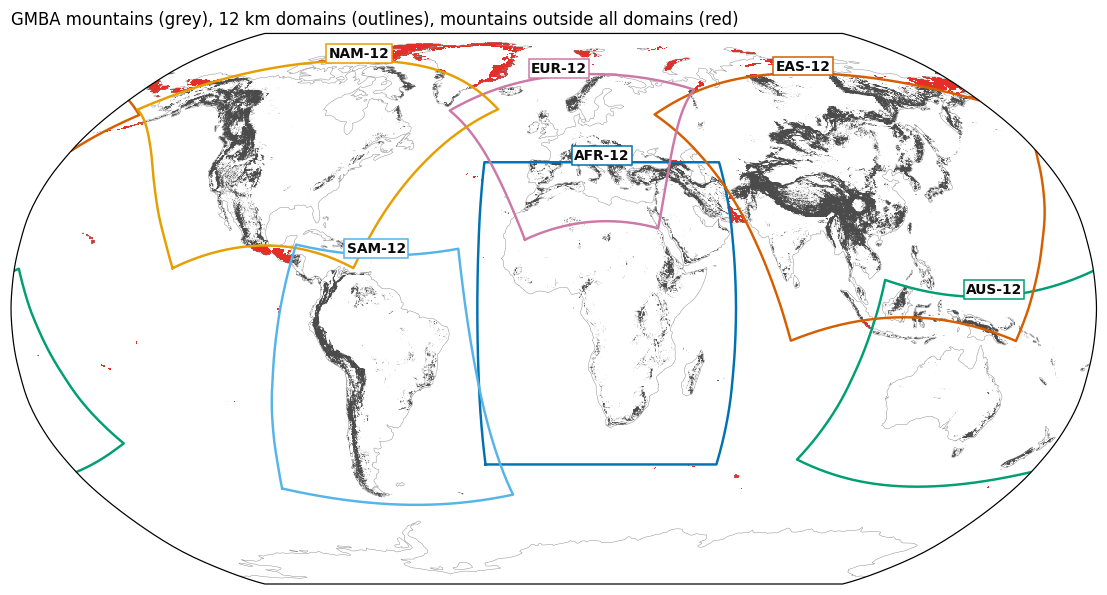

In [3]:
with nc.Dataset(f"{MTN}/masks/overlap_map_025deg.nc") as d:
    glat, glon, gf = d["lat"][:], d["lon"][:], d["mtn_frac"][:]
    cov = {dom: d[f"cov_{dom.replace('-', '_')}"][:] for dom in DOMAINS}
fig = plt.figure(figsize=(13, 6.5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global(); ax.add_feature(cfeature.COASTLINE, lw=0.3, color="#888")
ax.pcolormesh(glon, glat, np.ma.masked_equal(gf, 0), cmap="Greys", vmin=0, vmax=1.3, transform=ccrs.PlateCarree(), rasterized=True)
anyc = sum((cov[d] > 0).astype(int) for d in DOMAINS)
ax.pcolormesh(glon, glat, np.ma.masked_where(~((gf > 0) & (anyc == 0)), np.ones_like(gf)), cmap="Reds", vmin=0, vmax=1.5,
              transform=ccrs.PlateCarree(), rasterized=True)
for dom in DOMAINS:
    m = load_mask(dom)
    edge = np.concatenate([m["lonu"][0], m["lonu"][:, -1], m["lonu"][-1][::-1], m["lonu"][::-1, 0]]), \
           np.concatenate([m["lat"][0], m["lat"][:, -1], m["lat"][-1][::-1], m["lat"][::-1, 0]])
    ax.plot(*edge, color=DOM_COL[dom], lw=1.6, transform=ccrs.Geodetic())
    j, i = m["lat"].shape[0] - 1, m["lat"].shape[1] // 2
    ax.text(m["lonu"][j, i], m["lat"][j, i], dom, color="#0b0b0b", fontsize=9, fontweight="bold", ha="center", va="bottom",
            transform=ccrs.PlateCarree(), bbox=dict(fc="white", ec=DOM_COL[dom], lw=1, pad=1.5))
ax.set_title("GMBA mountains (grey), 12 km domains (outlines), mountains outside all domains (red)", loc="left")
plt.show()

## Per domain: mountain fraction, primary cells, model orography

/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


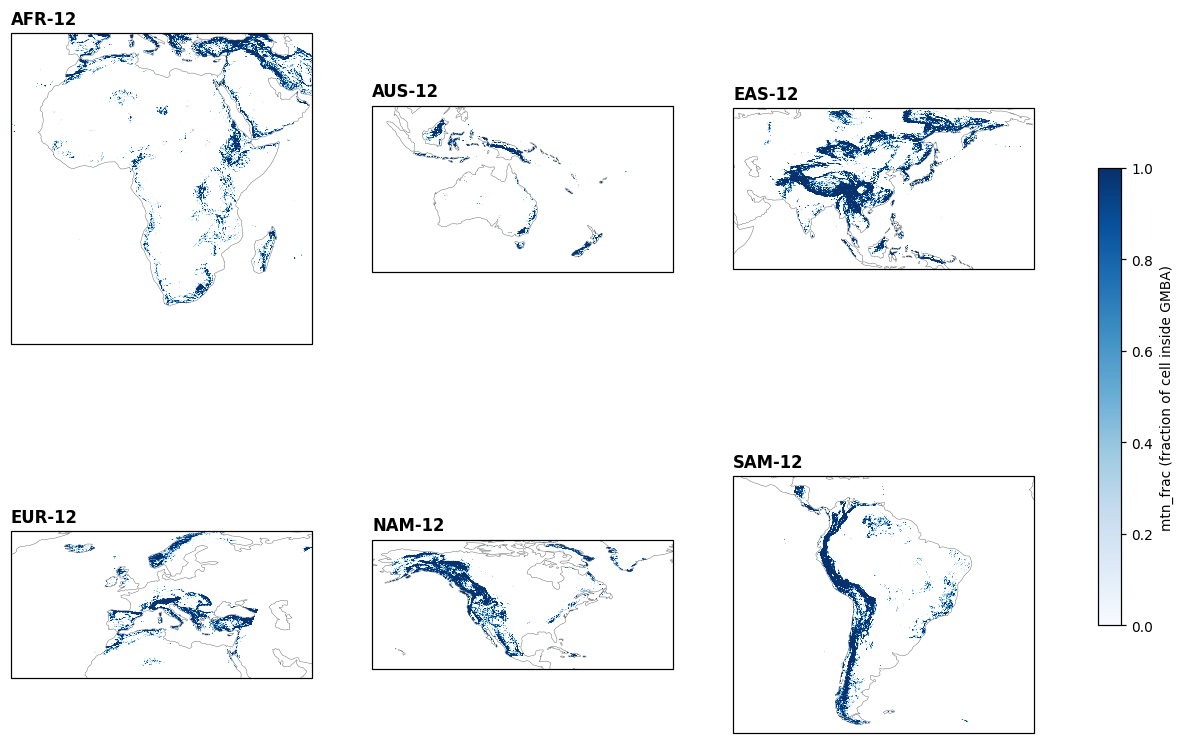

In [4]:
def domain_maps(value, title, cmap, vmin, vmax):
    """value(m) -> masked 2D array to draw for mask dict m."""
    fig = plt.figure(figsize=(15, 9))
    for k, dom in enumerate(DOMAINS):
        m = load_mask(dom)
        ax = fig.add_subplot(2, 3, k + 1, projection=ccrs.PlateCarree(central_longitude=m["clon"]))
        pm = ax.pcolormesh(m["lonu"], m["lat"], value(m), cmap=cmap, vmin=vmin, vmax=vmax,
                           transform=ccrs.PlateCarree(), shading="nearest", rasterized=True)
        ax.add_feature(cfeature.COASTLINE, lw=0.3, color="#666")
        ax.set_extent([m["lonu"].min(), m["lonu"].max(), np.nanmin(m["lat"]), np.nanmax(m["lat"])], ccrs.PlateCarree())
        ax.set_title(dom, loc="left", fontweight="bold")
    fig.colorbar(pm, ax=fig.axes, shrink=0.6, label=title)
    plt.show()

mountain = lambda m: m["mtn_frac"] > 0
domain_maps(lambda m: np.ma.masked_where(~mountain(m), m["mtn_frac"]), "mtn_frac (fraction of cell inside GMBA)", "Blues", 0, 1)

### EUR-12: how the mountain boundary is drawn on the model grid
`mtn_frac` = share of each 12 km cell inside the GMBA polygons (black outline), from 30 arc-second pixels.
Cells with `mtn_frac > 0` are extracted; grey = land cells outside GMBA. Right: zoom on the Alps, where the
partly covered cells (light blue) follow the GMBA line. Saved to `results/figures/EUR-12_mtn_frac.png`.

/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


EUR-12: 23172 cells with mtn_frac>0; share by bin: {'0-0.2': '22%', '0.2-0.4': '13%', '0.4-0.6': '12%', '0.6-0.8': '11%', '0.8-1.0': '41%'} | exactly 1: 26%


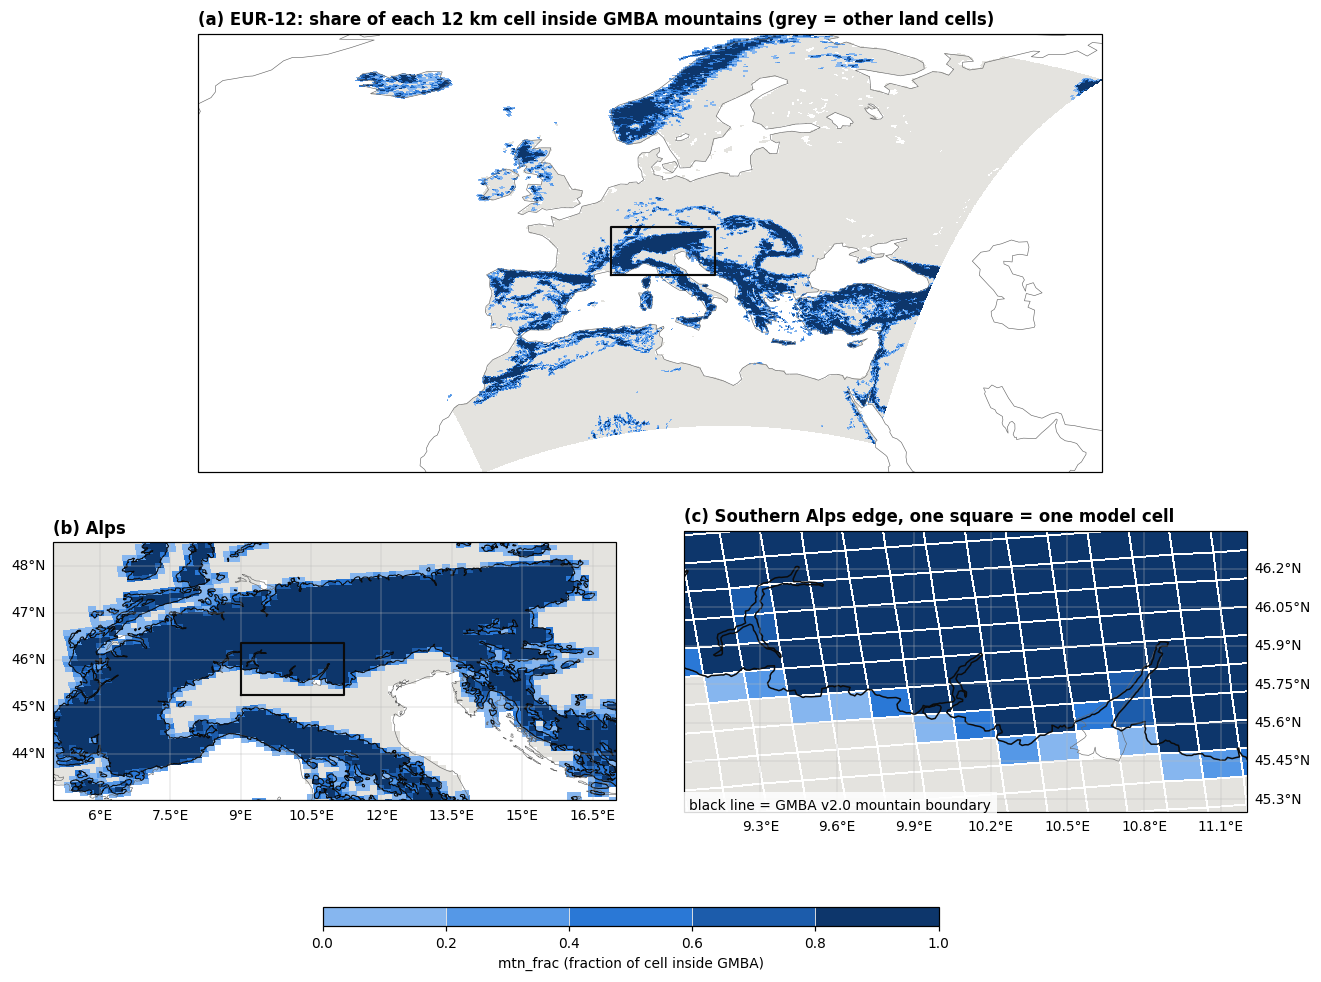

In [5]:
import geopandas as gpd
from matplotlib.colors import BoundaryNorm, ListedColormap
from shapely.geometry import box
from shapely import make_valid

dom = "EUR-12"
m = load_mask(dom)
frac = m["mtn_frac"]
# Ordinal blue ramp (light = small share, dark = whole cell); lightest step still visible on white.
BINS = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
cmap = ListedColormap(["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"])
norm = BoundaryNorm(BINS, cmap.N)
land = np.ma.masked_where(~((frac == 0) & (m["sftlf"] > 50)), np.ones_like(frac))

ZOOM = (5.0, 17.0, 43.0, 48.5)  # Alps: lon0, lon1, lat0, lat1
gmba = gpd.read_file(f"{MTN}/DEM_and_shp/GMBA_Inventory_v2.0_standard/GMBA_Inventory_v2.0_standard.shp")
zbox = box(ZOOM[0] - 1, ZOOM[2] - 1, ZOOM[1] + 1, ZOOM[3] + 1)
sub = gmba[gmba.intersects(zbox)].geometry.apply(make_valid)
outline = gpd.GeoSeries([sub.union_all().intersection(zbox)], crs=gmba.crs)

ZOOM2 = (9.0, 11.2, 45.25, 46.35)  # close-up: southern Alps edge north of the Po plain (lakes Como, Iseo, Garda)
fig = plt.figure(figsize=(14, 9.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.25, 1], hspace=0.06, wspace=0.12)
proj = ccrs.PlateCarree()
a0 = fig.add_subplot(gs[0, :], projection=ccrs.PlateCarree(central_longitude=m["clon"]))
a1 = fig.add_subplot(gs[1, 0], projection=proj)
a2 = fig.add_subplot(gs[1, 1], projection=proj)
axes = [a0, a1, a2]
for k, ax in enumerate(axes):
    ax.pcolormesh(m["lonu"], m["lat"], land, cmap=ListedColormap(["#e4e3df"]), transform=proj, shading="nearest", rasterized=True)
    pm = ax.pcolormesh(m["lonu"], m["lat"], np.ma.masked_where(frac <= 0, frac), cmap=cmap, norm=norm, transform=proj,
                       shading="nearest", rasterized=True, edgecolor="white" if k == 2 else "none", linewidth=0.6 if k == 2 else 0)
    ax.add_feature(cfeature.COASTLINE, lw=0.4, color="#666")
    ax.add_feature(cfeature.LAKES, facecolor="none", edgecolor="#666", lw=0.4)
    ax.grid(False)
def frame(ax, z):
    ax.plot([z[0], z[1], z[1], z[0], z[0]], [z[2], z[2], z[3], z[3], z[2]], color="#0b0b0b", lw=1.4, transform=proj)
a0.set_extent([m["lonu"].min(), m["lonu"].max(), np.nanmin(m["lat"]), np.nanmax(m["lat"])], proj)
frame(a0, ZOOM)
a0.set_title(f"(a) {dom}: share of each 12 km cell inside GMBA mountains (grey = other land cells)", loc="left", fontweight="bold")
for ax, z, t in [(a1, ZOOM, "(b) Alps"), (a2, ZOOM2, "(c) Southern Alps edge, one square = one model cell")]:
    ax.set_extent(z, proj)
    ax.add_geometries(outline.geometry, crs=proj, facecolor="none", edgecolor="#0b0b0b", linewidth=1.0 if ax is a2 else 0.7)
    ax.set_title(t, loc="left", fontweight="bold")
    gl = ax.gridlines(draw_labels=True, lw=0.3, color="#bbb"); gl.top_labels = False
    gl.left_labels, gl.right_labels = (True, False) if ax is a1 else (False, True)
frame(a1, ZOOM2)
a2.text(0.01, 0.01, "black line = GMBA v2.0 mountain boundary", transform=a2.transAxes, fontsize=9,
        bbox=dict(fc="white", ec="none", alpha=0.85))
fig.subplots_adjust(bottom=0.11)
cb = fig.colorbar(pm, cax=fig.add_axes([0.3, 0.035, 0.4, 0.018]), orientation="horizontal", ticks=BINS)
cb.set_label("mtn_frac (fraction of cell inside GMBA)")
n = (frac > 0).sum()
print(f"{dom}: {n} cells with mtn_frac>0; share by bin:",
      {f"{lo}-{hi}": f"{((frac > lo) & (frac <= hi)).sum() / n:.0%}" for lo, hi in zip(BINS[:-1], BINS[1:])},
      f"| exactly 1: {(frac >= 0.9999).sum() / n:.0%}")
fig.savefig(f"{MTN}/results/figures/EUR-12_mtn_frac.png", dpi=200, bbox_inches="tight")
plt.show()

`is_primary`: dark = cell counted for this domain in global statistics; light = mountain cell assigned to another domain.

/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


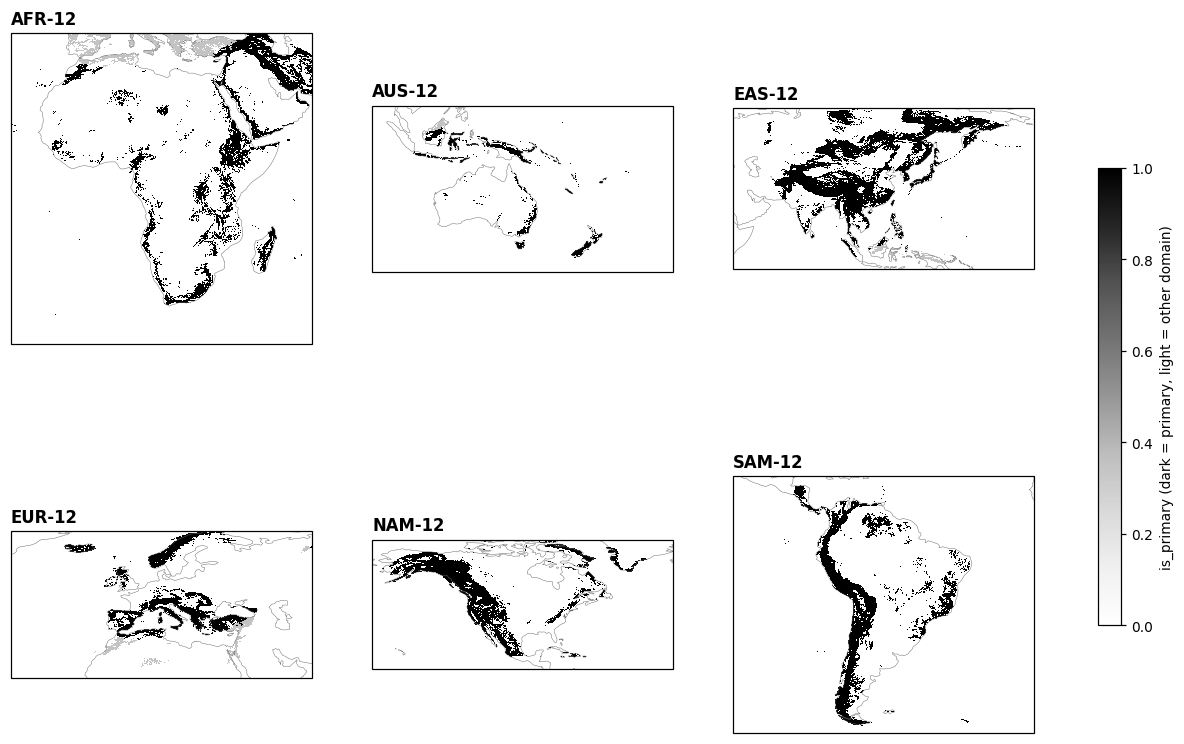

In [6]:
domain_maps(lambda m: np.ma.masked_where(~mountain(m), np.where(m["is_primary"] > 0, 1.0, 0.35)),
            "is_primary (dark = primary, light = other domain)", "Greys", 0, 1)

/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


/leonardo/home/userexternal/wtang001/.venv/lib64/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


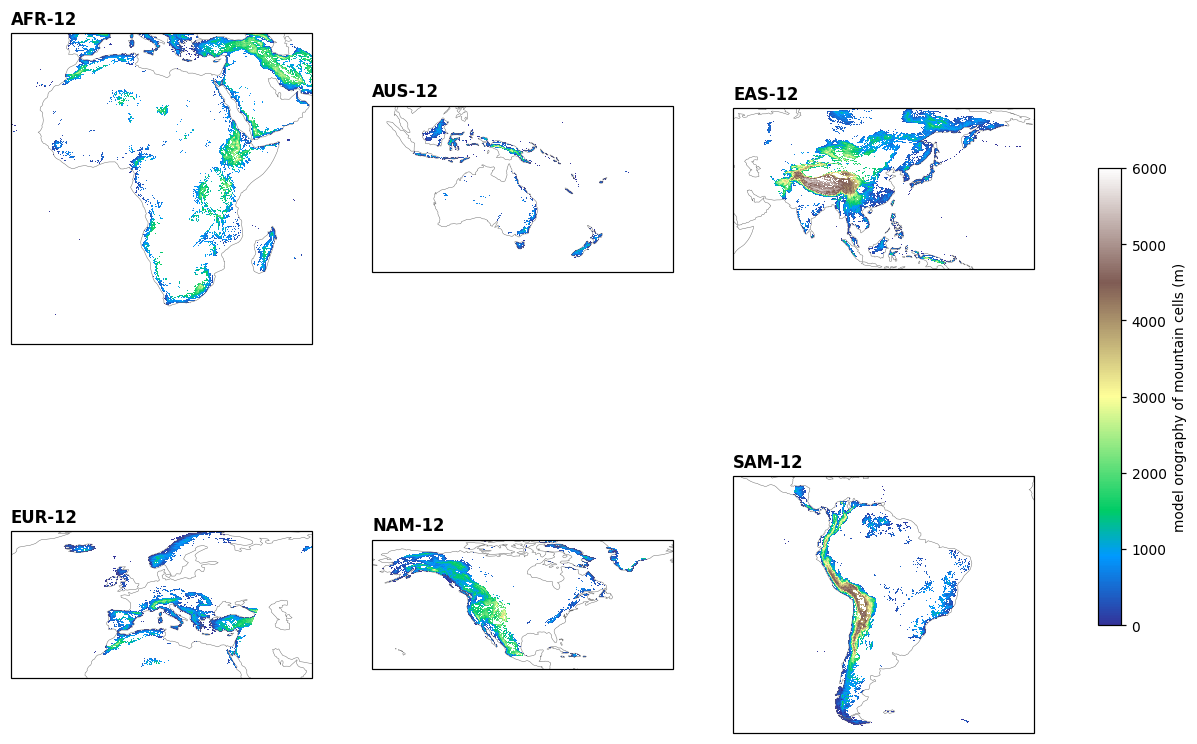

In [7]:
domain_maps(lambda m: np.ma.masked_where(~mountain(m), m["orog"]), "model orography of mountain cells (m)", "terrain", 0, 6000)

## Cells per elevation band (all cells with mtn_frac > 0)

In [8]:
edges = [0, 1000, 2000, 3000, 4000, 5000, np.inf]
labels = ["0-1000", "1000-2000", "2000-3000", "3000-4000", "4000-5000", ">5000"]
rows = []
for dom in DOMAINS:
    m = load_mask(dom); k = m["mtn_frac"] > 0
    z = np.maximum(m["orog"][k], 0); w = (m["mtn_frac"] * m["cell_area"])[k]
    b = np.digitize(z, edges[1:-1])
    rows.append(dict(domain=dom, cells=int(k.sum()), cells_frac_ge_05=int((m["mtn_frac"] >= 0.5).sum()), primary=int((m["is_primary"] > 0).sum()),
                     mtn_area_Mkm2=round(w.sum() / 1e6, 3), **{l: int((b == i).sum()) for i, l in enumerate(labels)}))
pd.DataFrame(rows).set_index("domain")

,cells,cells_frac_ge_05,primary,mtn_area_Mkm2,0-1000,1000-2000,2000-3000,3000-4000,4000-5000,>5000
domain,,,,,,,,,,
AFR-12,54343,27852,43188,3.788,27566,22355,4379,43,0,0
AUS-12,15787,9420,14417,1.294,13666,1681,403,37,0,0
EAS-12,115226,79869,109179,11.182,63051,25181,8628,5368,9154,3844
EUR-12,23172,13603,18677,2.035,17114,5588,470,0,0,0
NAM-12,45681,28762,45681,4.155,21567,18706,5182,226,0,0
SAM-12,32705,20734,32705,3.010,18327,5966,2864,3062,2468,18


## Largest GMBA Basic units not covered by any domain

In [9]:
u = pd.read_csv(f"{MTN}/masks/gmba_unit_primary.csv")
print("uncovered area %.2f M km2 in %d units" % (u[u.primary_domain == "NONE"].Area.sum() / 1e6, (u.primary_domain == "NONE").sum()))
u[u.primary_domain == "NONE"].sort_values("Area", ascending=False)[["MapName", "Level_02", "Level_03", "Area"]].head(20)

uncovered area 0.89 M km2 in 169 units


,MapName,Level_02,Level_03,Area
1731,King Christian X Land (nn),North America Arctic Islands,Greenland Kalaallit Nunaat,77454.79993
1730,Ellesmere Island (nn),North America Arctic Islands,Arctic Cordillera,57304.77401
448,Chukotka Mountains (nn),East Siberian Mountains,Chukotka Mountains,48869.67130
3597,Cordillera Costera del Sur (nn),American Cordillera (North America),Mexican Highlands,43061.46587
1638,Peary Land,North America Arctic Islands,Greenland Kalaallit Nunaat,31116.42488
1367,Victoria and Albert Mountains,North America Arctic Islands,Arctic Cordillera,28119.94873
837,Princess Margaret Mountains,North America Arctic Islands,Arctic Cordillera,27867.46865
21,Spitsbergen,Svalbard,Spitsbergen,25844.12780
1365,Northwest Ellesmere Island,North America Arctic Islands,Arctic Cordillera,24668.78992
0,Novaya Zemlya,Novaya Zemlya,NaN,20702.42471
